# Frozen-phonon amplitude series: E(Q), F(Q) and the Q → 0 force constants

Energy and generalized force of each symmetry-adapted basis mode at Q = 0.01, 0.02, 0.03, 0.05 Å (conv_thr 1e-10;
log 2026-10-17), for Y₂Ir₂O₇ (Γ₂⁻, 3 modes) and MnBi₂Te₄ (T₂⁻, 4 modes). Q is the displacement per Cartesian
component along the raw SMODES vector v (entries ±1).

- **ΔE(Q) = E(Q) − E(0) = ½kQ² + a₄Q⁴**, **f(Q) = v·[F(Q) − F(0)] = −kQ − bQ³** (b = 4a₄ if forces and energies agree).
  No odd terms: every mode is odd under inversion, a symmetry of the base, and v·F(0) = 0 (checked).
- **−Q** is the inversion image of +Q, so ΔE(−Q) = ΔE(Q), f(−Q) = −f(Q): the plots reflect the data.
- **Force constants** Φ_ij(Q) = −v_i·[F(Q v_j) − F(0)]/Q = Φ_ij + c_ij Q² + O(Q⁴) (no odd terms, for the same
  reason), so the forward difference is as accurate as a central one; Φ_ij is extrapolated to Q → 0 by a fit in Q²,
  and Φc = ω²Mc gives the frequencies.

In [1]:
# ============================================================================== settings
from pathlib import Path
DATA = Path("/Users/treycole/Repos/axion-phonon/data")
Y = DATA / "Y2Ir2O7/phonon/GM2-"
M = DATA / "MnBi2Te4/phonons"
MATERIALS = {
    "Y2Ir2O7": dict(
        prefix="Y2Ir2O7", nat=22, base=DATA / "Y2Ir2O7/base/lda/scf_conv1e-10_213998",
        masses={"Y": 88.90584, "Ir": 192.217, "O": 15.9994},
        series={  # mode label: {Q (Å): SCF folder}
            "1 (Y)": {0.01: Y / "mode1/Q_0.01A/lda/scf_nscf_conv1e-10_213999", 0.02: Y / "mode1/Q_0.02A/lda/scf_nscf_conv1e-10_214000",
                      0.03: Y / "mode1/Q_0.03A/lda/scf_nscf_conv1e-10_214001", 0.05: Y / "mode1/Q_0.05A/lda/scf_nscf_conv1e-10_214002"},
            "2 (Ir)": {0.01: Y / "mode2/Q_0.01A/lda/scf_nscf_conv1e-10_214003", 0.02: Y / "mode2/Q_0.02A/lda/scf_nscf_conv1e-10_214004",
                       0.03: Y / "mode2/Q_0.03A/lda/scf_nscf_conv1e-10_214005", 0.05: Y / "mode2/Q_0.05A/lda/scf_nscf_conv1e-10_214015"},
            "3 (O)": {0.01: Y / "mode3/Q_0.01A/lda/scf_nscf_conv1e-10_214016", 0.02: Y / "mode3/Q_0.02A/lda/scf_nscf_conv1e-10_214011",
                      0.03: Y / "mode3/Q_0.03A/lda/scf_nscf_conv1e-10_214012", 0.05: Y / "mode3/Q_0.05A/lda/scf_nscf_conv1e-10_214013"}}),
    "MnBi2Te4": dict(
        prefix="MnBi2Te4", nat=14, base=DATA / "MnBi2Te4/phonons/amplitude_series/base/out",
        masses={"Mn": 54.938044, "Bi": 208.9804, "Te": 127.60},
        series={
            "1 (Mn)": {0.01: M / "amplitude_series/T2-_p1_Q0.01/out", 0.02: M / "amplitude_series/T2-_p1_Q0.02/out",
                       0.03: M / "force_constants/T2-_p1_Q0.03/out", 0.05: M / "amplitude_series/T2-_p1_Q0.05/out"},
            "2 (Bi)": {0.01: M / "amplitude_series/T2-_p2_Q0.01/out", 0.02: M / "amplitude_series/T2-_p2_Q0.02/out",
                       0.03: M / "force_constants/T2-_p2_Q0.03/out", 0.05: M / "amplitude_series/T2-_p2_Q0.05/out"},
            "3 (Te1)": {0.01: M / "amplitude_series/T2-_p3_Q0.01/out", 0.02: M / "amplitude_series/T2-_p3_Q0.02/out",
                        0.03: M / "force_constants/T2-_p3_Q0.03/out", 0.05: M / "amplitude_series/T2-_p3_Q0.05/out"},
            "4 (Te2)": {0.01: M / "amplitude_series/T2-_p4_Q0.01/out", 0.02: M / "amplitude_series/T2-_p4_Q0.02/out",
                        0.03: M / "force_constants/T2-_p4_Q0.03/out", 0.05: M / "amplitude_series/T2-_p4_Q0.05/out"}}),
}
FIG_DIR = None                 # e.g. Path(".../paper/figures"); None: show only
# ======================================================================================

In [2]:
import re
import numpy as np
import matplotlib.pyplot as plt

RY_EV = 13.605693
RYBOHR_EVA = 13.605693 / 0.529177
CM = np.sqrt(1.602176634e-19 / 1e-20 / 1.66053907e-27) / (2 * np.pi * 2.99792458e10)   # sqrt(eV/Å²/amu) -> cm^-1


def positions(folder, prefix, nat):
    t = (folder / f"{prefix}.scf.in").read_text()
    rows = [l.split() for l in t.split("ATOMIC_POSITIONS angstrom")[1].strip().splitlines()[:nat]]
    return [r[0] for r in rows], np.array([[float(x) for x in r[1:4]] for r in rows])


def scf(folder, prefix, nat):
    t = (folder / f"{prefix}.scf.out").read_text()
    E = float(re.findall(r"!\s+total energy\s+=\s+(\S+)", t)[-1]) * RY_EV
    F = np.array(re.findall(r"atom\s+\d+ type\s+\d+\s+force =\s+(\S+)\s+(\S+)\s+(\S+)", t), float)[:nat] * RYBOHR_EVA
    return E, F


def load(mat):
    species, R0 = positions(mat["base"], mat["prefix"], mat["nat"])
    E0, F0 = scf(mat["base"], mat["prefix"], mat["nat"])
    m = np.array([mat["masses"][re.sub(r"\d", "", s)] for s in species])
    data = {}
    for label, runs in mat["series"].items():
        for Q, folder in sorted(runs.items()):
            _, R = positions(folder, mat["prefix"], mat["nat"])
            E, F = scf(folder, mat["prefix"], mat["nat"])
            data[label, Q] = dict(v=(R - R0) / Q, dE=E - E0, dF=F - F0, vF0=float(((R - R0) / Q * F0).sum()))
    return m, data


loaded = {name: load(mat) for name, mat in MATERIALS.items()}

In [3]:
# Per-mode table and fits: ΔE = ½k Q² + a₄Q⁴ and f = −kQ − bQ³ (b = 4a₄ if energies and forces agree)
fits = {}
for name, mat in MATERIALS.items():
    m, data = loaded[name]
    print(f"\n{name}\n{'mode':8s} {'Q (Å)':>6s} {'ΔE (meV)':>10s} {'f (eV/Å)':>10s} {'2ΔE/Q²':>9s} {'−f/Q':>9s} {'E/F':>7s} {'v·F(0)':>8s}")
    for label, runs in mat["series"].items():
        rows = []
        for Q in sorted(runs):
            d = data[label, Q]; f = float((d["v"] * d["dF"]).sum()); rows.append((Q, d["dE"], f))
            print(f"{label:8s} {Q:6.2f} {d['dE'] * 1e3:10.4f} {f:+10.5f} {2 * d['dE'] / Q**2:9.4f} {-f / Q:9.4f} "
                  f"{(2 * d['dE'] / Q**2) / (-f / Q):7.4f} {d['vF0']:+8.0e}")
        Q, dE, f = np.array(rows).T
        (kE, a4), *_ = np.linalg.lstsq(np.c_[0.5 * Q**2, Q**4], dE, rcond=None)
        (kF, b), *_ = np.linalg.lstsq(np.c_[-Q, -Q**3], f, rcond=None)
        fits[name, label] = dict(Q=Q, dE=dE, f=f, kE=kE, a4=a4, kF=kF, b=b)
        print(f"  fit: k_E = {kE:.3f}, k_F = {kF:.3f} eV/Å² (E/F {kE / kF:.4f}); a₄ = {a4:+.1f}, b = {b:+.1f} (4a₄ = {4 * a4:+.1f}) eV/Å⁴")


Y2Ir2O7
mode      Q (Å)   ΔE (meV)   f (eV/Å)    2ΔE/Q²      −f/Q     E/F   v·F(0)
1 (Y)      0.01    21.9495   -4.40315  438.9904  440.3148  0.9970   +0e+00
1 (Y)      0.02    88.0744   -8.82053  440.3721  441.0266  0.9985   +0e+00
1 (Y)      0.03   198.4622  -13.26947  441.0270  442.3157  0.9971   +0e+00
1 (Y)      0.05   553.9464  -22.32237  443.1571  446.4473  0.9926   +0e+00
  fit: k_E = 439.811, k_F = 440.001 eV/Å² (E/F 0.9996); a₄ = +669.3, b = +2578.1 (4a₄ = +2677.2) eV/Å⁴
2 (Ir)     0.01    24.6173   -4.92470  492.3465  492.4701  0.9997   +0e+00
2 (Ir)     0.02    98.5172   -9.83142  492.5860  491.5710  1.0021   +0e+00
2 (Ir)     0.03   221.2544  -14.70323  491.6765  490.1077  1.0032   +0e+00
2 (Ir)     0.05   611.5105  -24.27614  489.2084  485.5227  1.0076   +0e+00
  fit: k_E = 493.094, k_F = 492.710 eV/Å² (E/F 1.0008); a₄ = -777.2, b = -2875.6 (4a₄ = -3108.8) eV/Å⁴
3 (O)      0.01     7.5214   -1.49774  150.4273  149.7745  1.0044   +2e-14
3 (O)      0.02    30.0057   -2.994

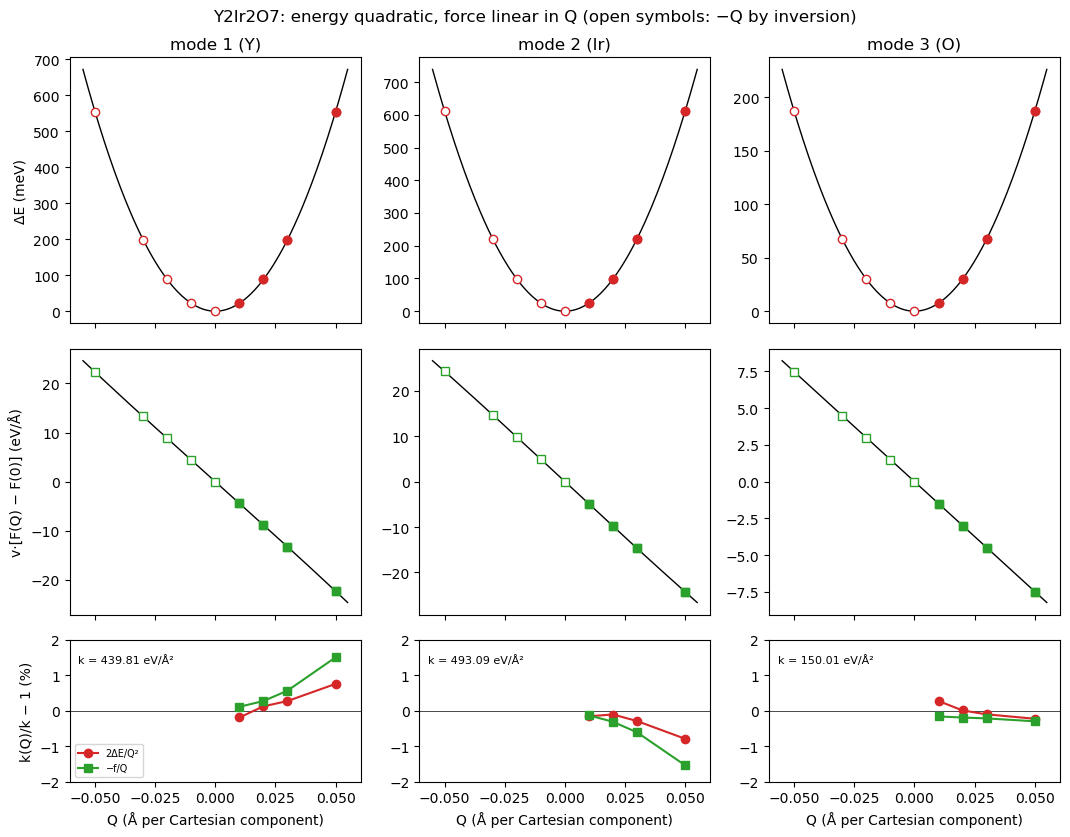

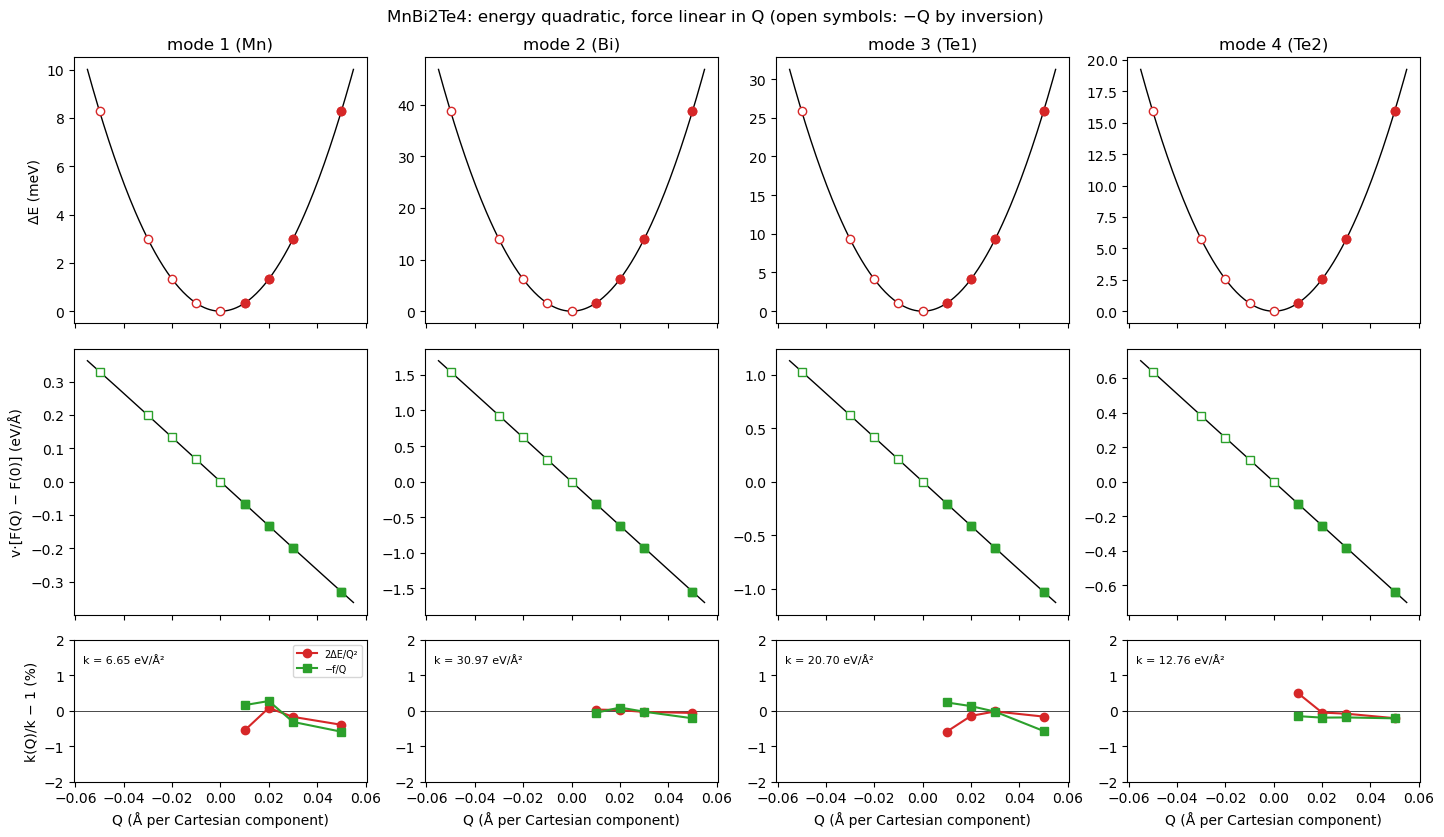

In [4]:
# E(Q), f(Q) and k(Q)/k − 1, one figure per material (−Q filled in by inversion)
for name, mat in MATERIALS.items():
    labels = list(mat["series"])
    fig, ax = plt.subplots(3, len(labels), figsize=(3.6 * len(labels), 8.5), sharex=True,
                           gridspec_kw=dict(height_ratios=[3, 3, 1.6]), squeeze=False)
    q = np.linspace(-0.055, 0.055, 201)
    for j, label in enumerate(labels):
        p = fits[name, label]; Q, dE, f = p["Q"], p["dE"], p["f"]
        a = ax[0, j]
        a.plot(q, (0.5 * p["kE"] * q**2 + p["a4"] * q**4) * 1e3, "k-", lw=1)
        a.plot(np.r_[-Q[::-1], 0, Q], np.r_[dE[::-1], 0, dE] * 1e3, "o", mfc="w", color="C3")
        a.plot(Q, dE * 1e3, "o", color="C3"); a.set_title(f"mode {label}")
        a = ax[1, j]
        a.plot(q, -p["kF"] * q - p["b"] * q**3, "k-", lw=1)
        a.plot(np.r_[-Q[::-1], 0, Q], np.r_[-f[::-1], 0, f], "s", mfc="w", color="C2"); a.plot(Q, f, "s", color="C2")
        a = ax[2, j]; k0 = p["kE"]
        a.axhline(0, color="k", lw=0.5)
        a.plot(Q, 100 * (2 * dE / Q**2 / k0 - 1), "o-", color="C3", label="2ΔE/Q²")
        a.plot(Q, 100 * (-f / Q / k0 - 1), "s-", color="C2", label="−f/Q")
        a.text(0.03, 0.9, f"k = {k0:.2f} eV/Å²", transform=a.transAxes, fontsize=8, va="top"); a.set_ylim(-2, 2)
        a.set_xlabel("Q (Å per Cartesian component)")
    ax[0, 0].set_ylabel("ΔE (meV)"); ax[1, 0].set_ylabel("v·[F(Q) − F(0)] (eV/Å)"); ax[2, 0].set_ylabel("k(Q)/k − 1 (%)")
    ax[2, 0].legend(fontsize=7)
    fig.suptitle(f"{name}: energy quadratic, force linear in Q (open symbols: −Q by inversion)"); fig.tight_layout()
    if FIG_DIR:
        fig.savefig(FIG_DIR / f"{name}_amplitude_series.pdf")
    plt.show()


Y2Ir2O7: Φ(Q -> 0) (eV/Å², basis ['1 (Y)', '2 (Ir)', '3 (O)']), max fit residual 0.033 eV/Å²
[[440.025  29.729  44.79 ]
 [ 29.721 492.734 -63.25 ]
 [ 44.755 -63.241 149.77 ]]
  Q = 0.01 Å: ω = [228.62 328.3  471.57] cm⁻¹, asymmetry 0.028%
  Q = 0.02 Å: ω = [228.51 328.53 471.47] cm⁻¹, asymmetry 0.114%
  Q = 0.03 Å: ω = [228.33 328.96 471.37] cm⁻¹, asymmetry 0.258%
  Q = 0.05 Å: ω = [227.77 330.34 471.04] cm⁻¹, asymmetry 0.714%
  Q -> 0:   ω = [228.65 328.2  471.57] cm⁻¹, asymmetry 0.007%

MnBi2Te4: Φ(Q -> 0) (eV/Å², basis ['1 (Mn)', '2 (Bi)', '3 (Te1)', '4 (Te2)']), max fit residual 0.028 eV/Å²
[[ 6.661  3.137  0.814  4.078]
 [ 3.117 30.979 19.105 -6.789]
 [ 0.809 19.128 20.752  2.066]
 [ 4.064 -6.793  2.063 12.734]]
  Q = 0.01 Å: ω = [ 17.95  82.8  128.89 143.5 ] cm⁻¹, asymmetry 0.168%
  Q = 0.02 Å: ω = [ 18.1   82.76 128.94 143.52] cm⁻¹, asymmetry 0.059%
  Q = 0.03 Å: ω = [ 17.76  82.74 128.73 143.33] cm⁻¹, asymmetry 0.074%
  Q = 0.05 Å: ω = [ 17.62  82.74 128.41 143.2 ] cm⁻¹, asymm

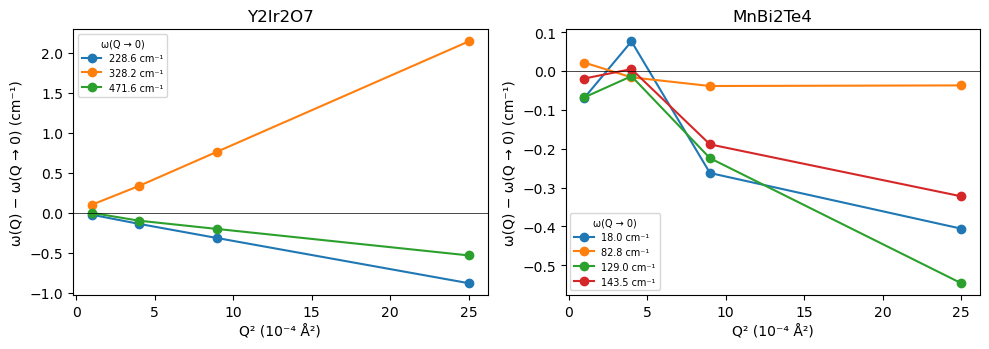

In [5]:
# Force-constant matrix at each Q, its Q -> 0 extrapolation (Φ_ij + c_ij Q²), and the frequencies
freq = {}
for name, mat in MATERIALS.items():
    m, data = loaded[name]
    labels = list(mat["series"]); Qs = sorted(mat["series"][labels[0]])
    V = [data[l, Qs[0]]["v"] for l in labels]
    Mass = np.array([[(m[:, None] * vi * vj).sum() for vj in V] for vi in V])
    L = np.linalg.cholesky(Mass); Li = np.linalg.inv(L)

    def omegas(P):
        w2 = np.linalg.eigvalsh(Li @ ((P + P.T) / 2) @ Li.T)
        return np.sign(w2) * np.sqrt(np.abs(w2)) * CM

    Phi = np.array([[[-(V[i] * data[labels[j], Q]["dF"]).sum() / Q for j in range(len(labels))] for i in range(len(labels))]
                    for Q in Qs])
    A = np.c_[np.ones(len(Qs)), np.array(Qs)**2]
    coef = np.linalg.lstsq(A, Phi.reshape(len(Qs), -1), rcond=None)[0]
    P0 = coef[0].reshape(Phi.shape[1:])
    resid = np.abs(Phi.reshape(len(Qs), -1) - A @ coef).max()
    freq[name] = dict(Qs=Qs, w=np.array([omegas(P) for P in Phi]), w0=omegas(P0))
    print(f"\n{name}: Φ(Q -> 0) (eV/Å², basis {labels}), max fit residual {resid:.3f} eV/Å²")
    print(np.array2string(P0, precision=3, suppress_small=True))
    for Q, P, w in zip(Qs, Phi, freq[name]["w"]):
        print(f"  Q = {Q:.2f} Å: ω = {np.round(w, 2)} cm⁻¹, asymmetry {np.abs(P - P.T).max() / np.abs(P).max():.3%}")
    print(f"  Q -> 0:   ω = {np.round(freq[name]['w0'], 2)} cm⁻¹, asymmetry {np.abs(P0 - P0.T).max() / np.abs(P0).max():.3%}")

fig, ax = plt.subplots(1, len(MATERIALS), figsize=(10, 3.6))
for a, (name, fr) in zip(np.atleast_1d(ax), freq.items()):
    q2 = np.array(fr["Qs"])**2
    for n in range(fr["w"].shape[1]):
        a.plot(q2 * 1e4, fr["w"][:, n] - fr["w0"][n], "o-", label=f"{fr['w0'][n]:.1f} cm⁻¹")
    a.axhline(0, color="k", lw=0.5); a.set_xlabel("Q² (10⁻⁴ Å²)"); a.set_ylabel("ω(Q) − ω(Q → 0) (cm⁻¹)")
    a.set_title(name); a.legend(fontsize=7, title="ω(Q → 0)", title_fontsize=7)
fig.tight_layout()
if FIG_DIR:
    fig.savefig(FIG_DIR / "frequencies_vs_Q2.pdf")
plt.show()

**Reading the plots.** k(Q)/k − 1: a quartic term makes 2ΔE/Q² drift as k + 2a₄Q² and −f/Q as k + 4a₄Q², twice as
fast, so the two fan out from the harmonic k. ω(Q) against Q²: straight lines whose intercepts are the reported
frequencies; their spread at Q = 0.01 Å is the finite-difference error the extrapolation removes.